# Level 2 - Task 2: Decision Trees for Classification
**Codveda ML Internship**

**Goal:** predict the species of an iris flower (setosa, versicolor, virginica) from its measurements.

**Dataset:** Codveda's `iris.csv` - 150 flowers, 4 measurements (sepal and petal length/width), 3 species, 50 of each.

**Steps:** 1) train a tree, 2) visualise it, 3) prune it to prevent overfitting, 4) evaluate with accuracy and F1-score.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score, classification_report

DATA_DIR = "../data"  # NB
df = pd.read_csv(f"{DATA_DIR}/iris.csv")
print("Shape:", df.shape, "| Missing:", int(df.isna().sum().sum()), "| Duplicates:", int(df.duplicated().sum()))
print(df["species"].value_counts().to_string())

X = df.drop(columns="species"); y = df["species"]
# stratify keeps the same species mix in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Shape: (150, 5) | Missing: 0 | Duplicates: 3
species
setosa        50
versicolor    50
virginica     50
Train: (120, 4) | Test: (30, 4)


**What this means:** The data is clean and perfectly balanced, and a tree does not need scaling or encoding, so preprocessing is minimal. `stratify=y` keeps the species mix equal in train and test.

## Step 1: Train an unpruned tree

In [2]:
full_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("Depth:", full_tree.get_depth(), "| Leaves:", full_tree.get_n_leaves())
print("Train accuracy:", round(full_tree.score(X_train, y_train), 3))
print("Test accuracy :", round(full_tree.score(X_test, y_test), 3))

Depth: 5 | Leaves: 8
Train accuracy: 1.0
Test accuracy : 0.933


**What this means:** With no limits, a tree keeps splitting until every training flower is classified correctly (train accuracy 1.0). That can mean it memorises quirks of the training set, which is **overfitting**.

## Step 2: Visualise the tree

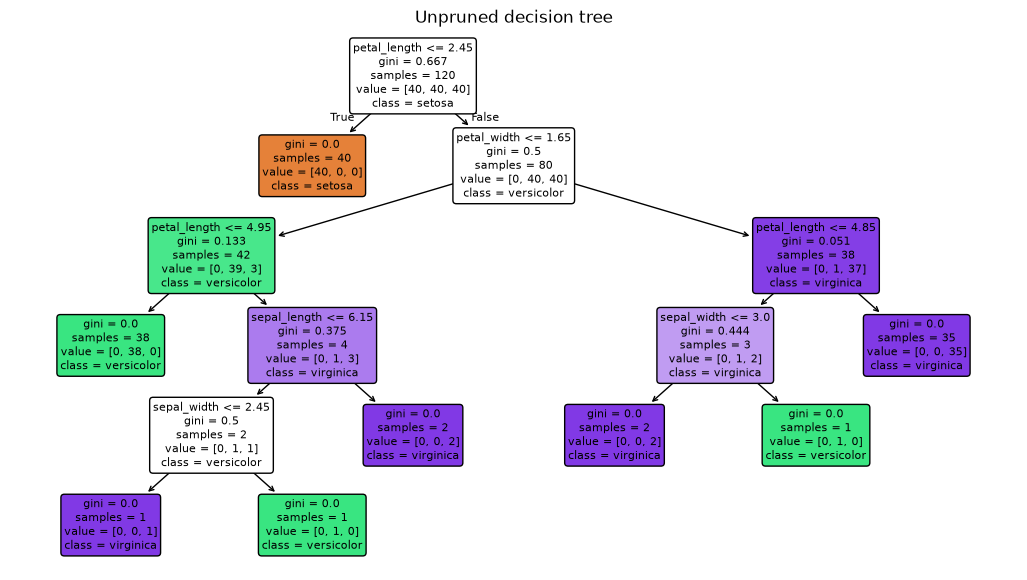

In [3]:
plt.figure(figsize=(13, 7))
plot_tree(full_tree, feature_names=X.columns, class_names=full_tree.classes_, filled=True, rounded=True, fontsize=8)
plt.title("Unpruned decision tree"); plt.show()

**What this means:** Each box asks a yes/no question about one measurement (for example a petal width threshold). Colour shows the majority species and the `gini` value shows impurity (0 means the box is pure). Petal measurements do most of the work.

## Step 3: Prune the tree

Best CV accuracy: 0.942 | chosen ccp_alpha: 0.0081
Pruned depth: 4 | Leaves: 6


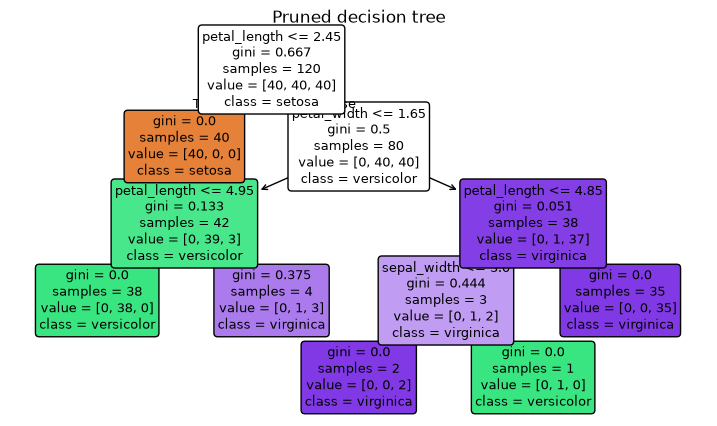

In [4]:
# Cost-complexity pruning: a larger ccp_alpha removes more branches.
# We choose it using 5-fold cross-validation on the TRAINING data only ("one standard error" rule):
# take the most pruned tree whose CV score is within one standard error of the best score.
alphas = np.unique(np.round(full_tree.cost_complexity_pruning_path(X_train, y_train).ccp_alphas, 4))
scores = [cross_val_score(DecisionTreeClassifier(random_state=42, ccp_alpha=a), X_train, y_train, cv=5) for a in alphas]
means = np.array([sc.mean() for sc in scores]); se = scores[int(np.argmax(means))].std() / np.sqrt(5)
best_alpha = alphas[means >= means.max() - se].max()
print("Best CV accuracy: %.3f | chosen ccp_alpha: %s" % (means.max(), best_alpha))

pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha).fit(X_train, y_train)
print("Pruned depth:", pruned.get_depth(), "| Leaves:", pruned.get_n_leaves())

plt.figure(figsize=(9, 5))
plot_tree(pruned, feature_names=X.columns, class_names=pruned.classes_, filled=True, rounded=True, fontsize=9)
plt.title("Pruned decision tree"); plt.show()

**What this means:** Pruning cuts branches that add little accuracy, giving a smaller tree that is easier to explain and less likely to overfit. We pick the amount of pruning with cross-validation on the training data, so the test set stays untouched. We choose the *simplest* tree whose score is within one standard error of the best, because a smaller tree that performs equally well is preferred.

## Step 4: Evaluate

In [5]:
rows = {}
for name, m in [("Unpruned", full_tree), ("Pruned", pruned)]:
    p = m.predict(X_test)
    rows[name] = {"Leaves": m.get_n_leaves(),
                  "CV accuracy (train)": cross_val_score(m, X_train, y_train, cv=5).mean(),
                  "Test accuracy": accuracy_score(y_test, p),
                  "Test F1 (macro)": f1_score(y_test, p, average="macro")}
print(pd.DataFrame(rows).T.round(3))
print()
print(classification_report(y_test, pruned.predict(X_test)))

          Leaves  CV accuracy (train)  Test accuracy  Test F1 (macro)
Unpruned     8.0                0.942          0.933            0.933
Pruned       6.0                0.942          0.967            0.967

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



**What this means:**
- **Accuracy:** share of flowers classified correctly.
- **F1-score:** balances precision and recall per species; "macro" averages the three species equally.
- With only 30 test flowers, one mistake moves accuracy by about 3 points, so differences between the two trees are small. The better comparison is the cross-validation score and the tree size.

## Conclusion
- A decision tree separates iris species very well, mainly using petal measurements.
- The pruned tree is simpler and performs about as well as the full tree, so the extra branches were not needed.
- Next steps: compare with a Random Forest (Level 3), which averages many trees for more stable results.